In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.datasets import load_iris
from keras.layers import Flatten, Dense, BatchNormalization, Dropout, Reshape
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [2]:
data = load_iris()
x = data.data
y = data.target

In [3]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state= 42)

In [4]:
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [5]:
input = keras.Input(shape=(x_train.shape[1],))
x = Dense(64, activation="relu")(input)
x = Dense(64, activation="relu")(x)
x = Dropout(0.5)(x)
x = Dense(64, activation="relu")(x)
x = Dropout(0.5)(x)
x = Dense(32, activation="relu")(x)
x = Dropout(0.5)(x)
x = Dense(16, activation="relu")(x)
x = Dropout(0.5)(x)
x = Dense(8, activation="relu")(x)
x = Dropout(0.5)(x)
output = Dense(4, activation="linear")(x)
model = keras.Model(inputs=input, outputs=output)

In [6]:
model.compile(optimizer="adam", loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])

In [9]:
history = model.fit(x_train, y_train, epochs=300, batch_size=32, validation_data=(x_test, y_test))

Epoch 1/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 203ms/step - accuracy: 0.5048 - loss: 1.1124 - val_accuracy: 0.7111 - val_loss: 1.0939
Epoch 2/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 68ms/step - accuracy: 0.4667 - loss: 1.1757 - val_accuracy: 0.7111 - val_loss: 1.0946
Epoch 3/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step - accuracy: 0.4857 - loss: 1.1034 - val_accuracy: 0.7111 - val_loss: 1.0856
Epoch 4/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 188ms/step - accuracy: 0.5429 - loss: 1.1233 - val_accuracy: 0.7111 - val_loss: 1.0737
Epoch 5/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 117ms/step - accuracy: 0.5714 - loss: 1.1050 - val_accuracy: 0.7111 - val_loss: 1.0624
Epoch 6/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5238 - loss: 1.0438 - val_accuracy: 0.7111 - val_loss: 1.0420
Epoch 7/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.5238 - loss: 1.0616 - val_accuracy: 0.7111 - val_loss: 1.0178
Epoch 8/300
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.5143 - loss: 1.0586 - val_accuracy: 0.7111 - val_l

In [19]:
count = 0
miss = 0
for i in model.predict(x_test):
    predicted = np.argmax(i)
    label = y_test[count]
    print("predicted:", predicted, "label:", label)
    if(predicted != label): miss = miss + 1
    count = count + 1
print("number of miss:", miss)

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 154ms/step
predicted: 1 label: 1
predicted: 0 label: 0
predicted: 2 label: 2
predicted: 1 label: 1
predicted: 1 label: 1
predicted: 0 label: 0
predicted: 1 label: 1
predicted: 2 label: 2
predicted: 2 label: 1
predicted: 1 label: 1
predicted: 2 label: 2
predicted: 0 label: 0
predicted: 0 label: 0
predicted: 0 label: 0
predicted: 0 label: 0
predicted: 1 label: 1
predicted: 2 label: 2
predicted: 1 label: 1
predicted: 1 label: 1
predicted: 2 label: 2
predicted: 0 label: 0
predicted: 2 label: 2
predicted: 0 label: 0
predicted: 2 label: 2
predicted: 2 label: 2
predicted: 2 label: 2
predicted: 2 label: 2
predicted: 2 label: 2
predicted: 0 label: 0
predicted: 0 label: 0
predicted: 0 label: 0
predicted: 0 label: 0
predicted: 1 label: 1
predicted: 0 label: 0
predicted: 0 label: 0
predicted: 2 label: 2
predicted: 1 label: 1
predicted: 0 label: 0
predicted: 0 label: 0
predicted: 0 label: 0
predicted: 2 label: 2
predicted: 1 label: 1
predicted: 1 label: 1
predicted: 0 la

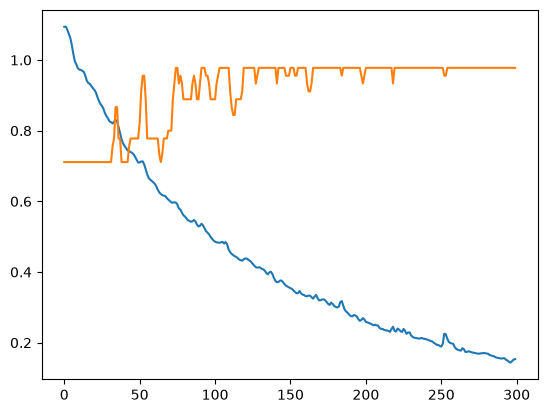

In [28]:
plt.plot(history.history["val_loss"])
plt.plot(history.history["val_accuracy"])
plt.show()